# Data exploration
Amazon video game ratings. Duplicates and missing ratings are removed, and only users that appear in the test set are kept.

In [2]:
import sys
sys.path.append("..")

from hybrid_recommenders.data import load_train_and_test_ratings

DATA_FOLDER = "../data"
train_df, test_df = load_train_and_test_ratings(f"{DATA_FOLDER}/train_video_games.parquet",
                                                f"{DATA_FOLDER}/test_video_games.parquet")

import numpy as np
import pandas as pd

from hybrid_recommenders.plotting import plot_rating_counts

In [3]:
number_of_users = train_df["user_id"].nunique()
number_of_items = train_df["item_id"].nunique()
sparsity = 1 - len(train_df) / (number_of_users * number_of_items)

pd.Series({
    "training ratings": len(train_df),
    "test ratings": len(test_df),
    "users": number_of_users,
    "items": number_of_items,
    "mean rating": train_df["rating"].mean(),
    "sparsity (%)": sparsity * 100,
    "ratings >= 4 (%)": (train_df["rating"] >= 4).mean() * 100,
    "ratings >= 3 (%)": (train_df["rating"] >= 3).mean() * 100,
}).round(2)

training ratings    26580.00
test ratings         6645.00
users                1389.00
items                 932.00
mean rating             4.23
sparsity (%)           97.95
ratings >= 4 (%)       79.16
ratings >= 3 (%)       89.85
dtype: float64

## Long tail

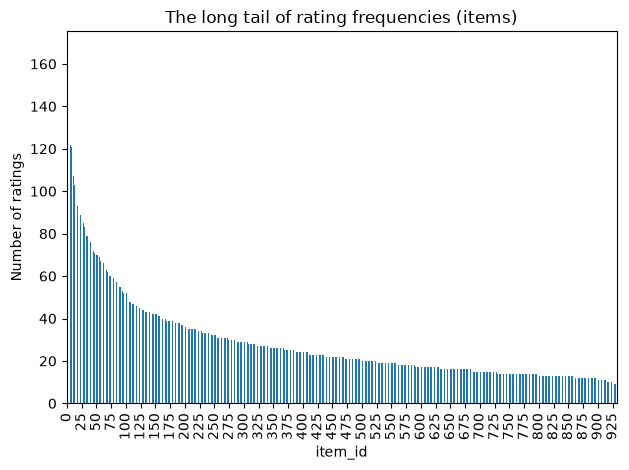

In [4]:
plot_rating_counts(train_df, "item_id", "The long tail of rating frequencies (items)")

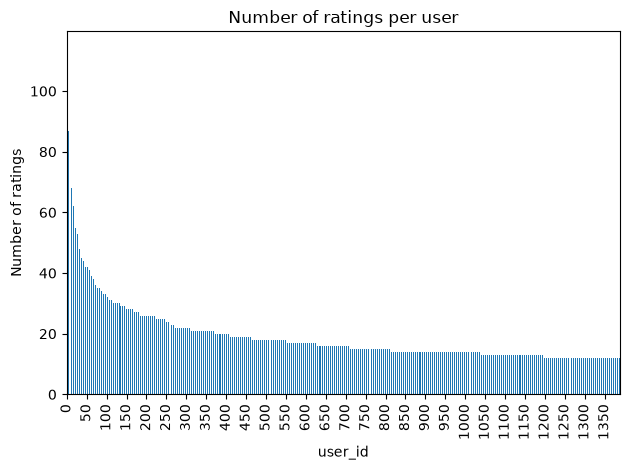

In [5]:
plot_rating_counts(train_df, "user_id", "Number of ratings per user", tick_every=50)

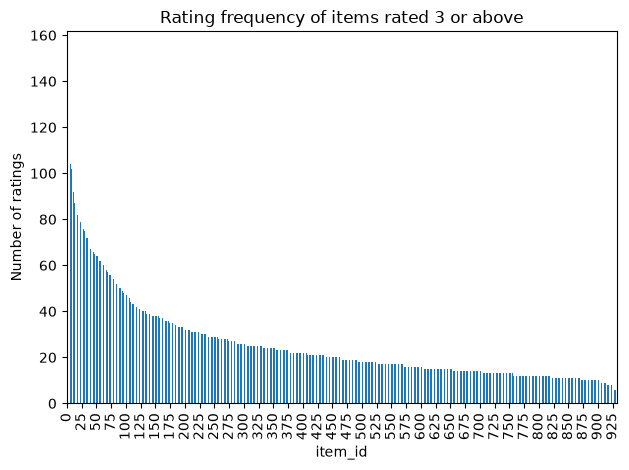

In [6]:
plot_rating_counts(train_df[train_df["rating"] >= 3], "item_id", "Rating frequency of items rated 3 or above")

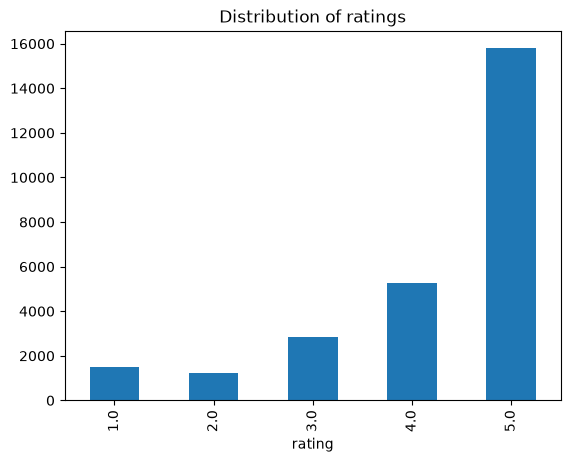

In [7]:
train_df["rating"].value_counts().sort_index().plot(kind="bar", title="Distribution of ratings");

## Top 5 items by number of high ratings (>= 3)

In [8]:
high_ratings = train_df[train_df["rating"] >= 3]
high_rating_statistics = high_ratings.groupby("item_id")["rating"].agg(number_of_high_ratings="count", average_rating="mean")

top_5_items = high_rating_statistics.sort_values("number_of_high_ratings", ascending=False).head(5)
top_5_items.sort_values("average_rating", ascending=False)

,number_of_high_ratings,average_rating
item_id,,
B00BGA9WK2,136,4.720588
B07YBXFDYN,146,4.712329
B0086VPUHI,154,4.694805
B007CM0K86,123,4.682927
B00BN5T30E,150,4.626667


## Rating distribution in train and test

In [9]:
rating_distribution = pd.DataFrame({
    "train (%)": train_df["rating"].value_counts(normalize=True).sort_index() * 100,
    "test (%)": test_df["rating"].value_counts(normalize=True).sort_index() * 100,
}).round(2)
rating_distribution

,train (%),test (%)
rating,,
1.0,5.56,5.54
2.0,4.59,4.50
3.0,10.68,10.68
4.0,19.76,20.15
5.0,59.41,59.13


In [10]:
pd.DataFrame({
    "train": [train_df["user_id"].nunique(), train_df["item_id"].nunique(), len(train_df),
              train_df.groupby("user_id")["item_id"].count().mean()],
    "test": [test_df["user_id"].nunique(), test_df["item_id"].nunique(), len(test_df),
             test_df.groupby("user_id")["item_id"].count().mean()],
}, index=["users", "items", "ratings", "average ratings per user"]).round(1)

,train,test
users,1389.0,1389.0
items,932.0,927.0
ratings,26580.0,6645.0
average ratings per user,19.1,4.8
